## ICD-code based experiments

In [1]:
import pandas as pd
DATA_PATH = "data" # "your-path-to-data"
class settings:
  def __init__(self):
    self.iter=10
    self.path1="experiment_main100"
    self.path2="experiment_code100"
    self.title1 = "with ICD descriptions"
    self.title2 = "with ICD codes"
    self.dataname = "INA"
    self.metrics = ["AUC","AUPRC", "F1","PPV","Sensitivity","Specificity", "NPV", "MCC","Accuracy", 'Brier', 'CM']
    self.methods = ['STATIC+TF-IDF' ,'STATIC+BOW', 'STATIC+BiPadLSTM','STATIC+Med2Vec','STATIC+Dipole',
                    'STATIC+CEHR-BERT','STATIC+DOME','STATIC+GRU']

args = settings()

method_styles = {
    "STATIC": {"color": "#1f77b4", "linestyle": "-"},
    "STATIC+BINARY": {"color": "#ff7f0e", "linestyle": "-"},
    "STATIC+FREQUENCY": {"color": "#2ca02c", "linestyle": "--"},
    "STATIC+EVENT-CNT": {"color": "#ff7f0e", "linestyle": "--"},
    "STATIC+TF-IDF": {"color": "#8c564b", "linestyle": "--"},
    "STATIC+BOW": {"color": "#2ca02c", "linestyle": "-"},
    "STATIC+BiPadLSTM": {"color": "#d62728", "linestyle": "-"},
    "STATIC+Med2Vec": {"color": "#9467bd", "linestyle": "--"},
    "STATIC+Dipole": {"color": "#1f77b4", "linestyle": "--"},
    "STATIC+CEHR-BERT": {"color": "#9467bd", "linestyle": "-"},
    "STATIC+DOME": {"color":  "#8c564b", "linestyle": "-"},
    "STATIC+GRU": {"color": "#d62728", "linestyle": "--"},
}

## Side-by-side radar plot

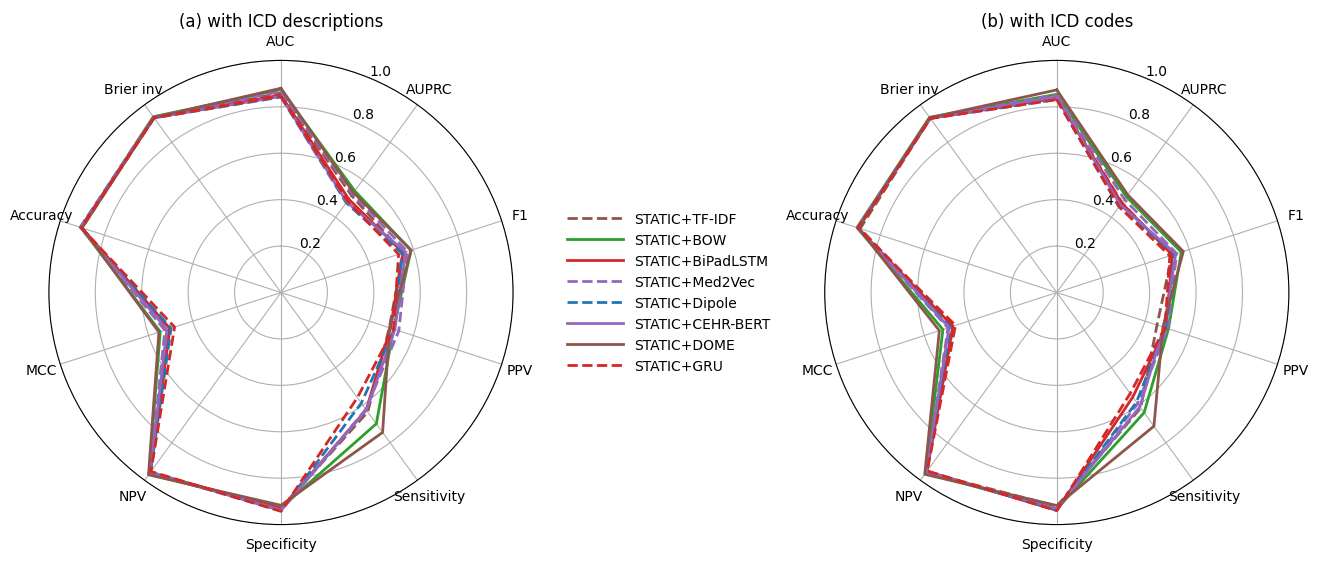

(<Figure size 1600x900 with 3 Axes>,
 [<PolarAxes: title={'center': '(a) with ICD descriptions'}>,
  <PolarAxes: title={'center': '(b) with ICD codes'}>])

In [2]:
from scripts.plotting import plot_radars
table1 = pd.read_csv(f"{args.path1}/result_table_{args.dataname}_ITER{args.iter}.csv",index_col=0,).drop(columns=['Confusion matrix']).apply(lambda col: col.str[0:5])
table2 = pd.read_csv(f"{args.path2}/result_table_{args.dataname}_ITER{args.iter}.csv",index_col=0,).drop(columns=['Confusion matrix']).apply(lambda col: col.str[0:5])
table1['Brier inv'] = table1['Brier'].apply(lambda x: f"{1-float(x)}")
table1.drop(columns=['Brier'], inplace=True)
table2['Brier inv'] = table2['Brier'].apply(lambda x: f"{1-float(x)}")
table2.drop(columns=['Brier'], inplace=True)
plot_radars(table1.loc[args.methods], table2.loc[args.methods], method_styles, titles=["(a) " + args.title1, "(b) " + args.title2])


## Get results from tables

In [3]:
import pandas as pd
df_mean_1 = pd.DataFrame()
df_std_1 = pd.DataFrame()
df_mean_2 = pd.DataFrame()
df_std_2 = pd.DataFrame()
for m in args.methods:
    df_mean_1 = pd.concat([df_mean_1, pd.DataFrame(pd.read_csv(f"{args.path1}/summary_{args.dataname}_{m}_ITER{args.iter}.csv")['mean'].values, columns=[m])], axis = 1)
    df_std_1 = pd.concat([df_std_1, pd.DataFrame(pd.read_csv(f"{args.path1}/summary_{args.dataname}_{m}_ITER{args.iter}.csv")['std_between_runs'].values, columns=[m])], axis = 1)
    df_mean_2 = pd.concat([df_mean_2, pd.DataFrame(pd.read_csv(f"{args.path2}/summary_{args.dataname}_{m}_ITER{args.iter}.csv")['mean'].values, columns=[m])], axis = 1)
    df_std_2 = pd.concat([df_std_2, pd.DataFrame(pd.read_csv(f"{args.path2}/summary_{args.dataname}_{m}_ITER{args.iter}.csv")['std_between_runs'].values, columns=[m])], axis = 1)
df_mean_1.index = args.metrics[:-1]
df_std_1.index = args.metrics[:-1]
df_mean_1 = df_mean_1.T
df_std_1 = df_std_1.T
df_mean_2.index = args.metrics[:-1]
df_std_2.index = args.metrics[:-1]
df_mean_2 = df_mean_2.T
df_std_2 = df_std_2.T

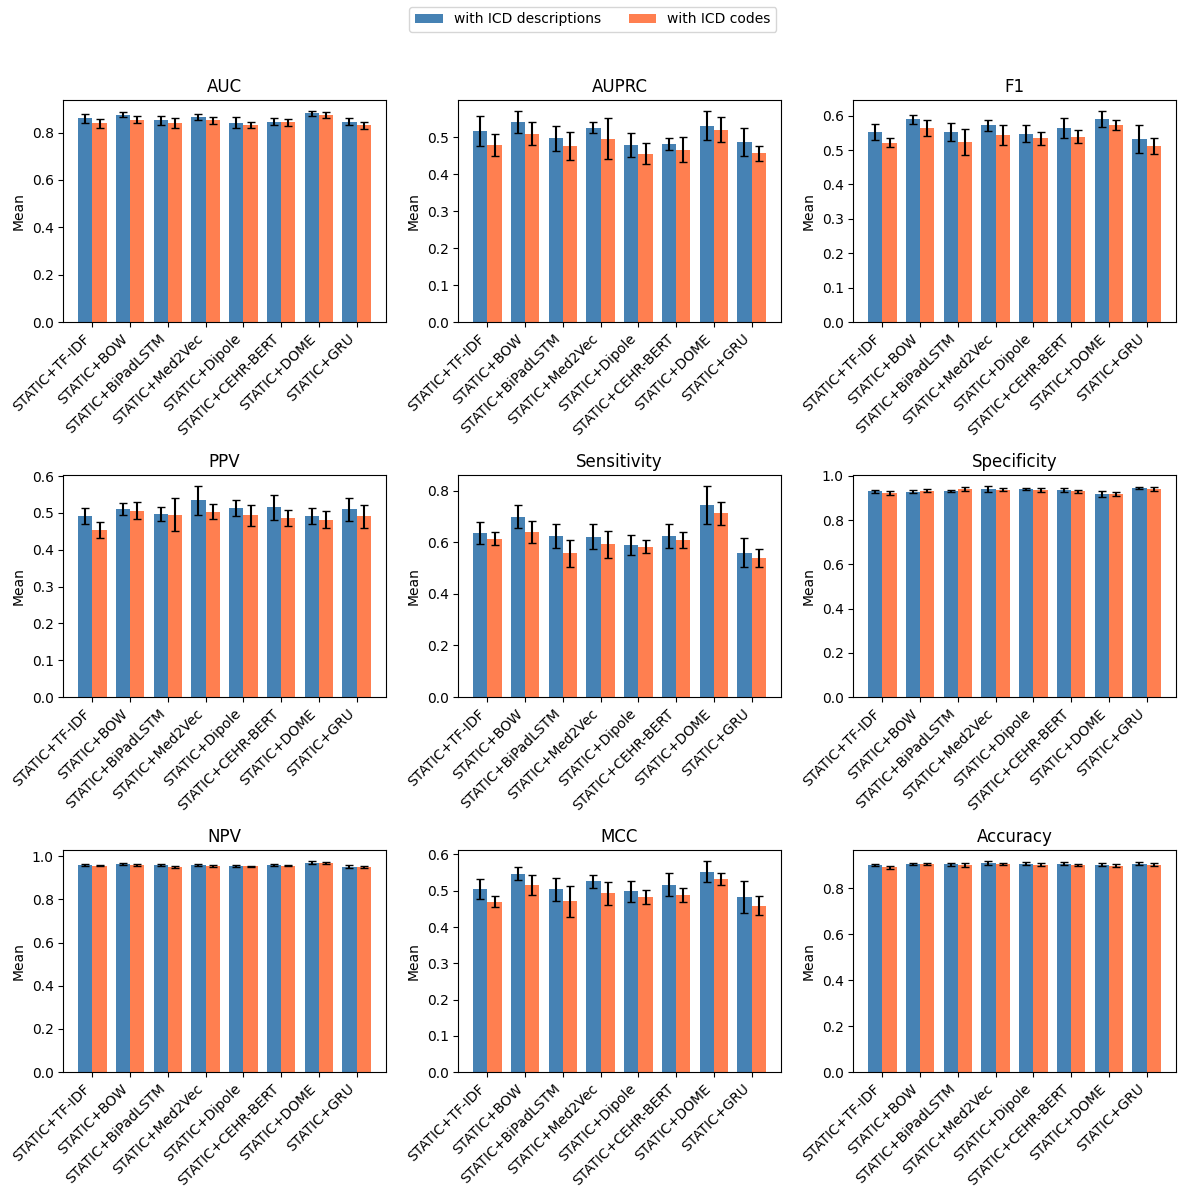

In [4]:
import numpy as np
import matplotlib.pyplot as plt

methods = df_mean_1.index
metrics = list(df_mean_1.columns[:-1])
x = np.arange(len(methods))
larghezza = 0.38

for start in range(0, len(metrics), 12):
    fig, assi = plt.subplots(3, 3, figsize=(12, 12))
    assi = assi.flat

    for ax, metrica in zip(assi, metrics[start:start + 12]):
        ax.bar(
            x - larghezza / 2,
            df_mean_1.loc[methods, metrica],
            larghezza,
            yerr=df_std_1.loc[methods, metrica],
            capsize=3,
            label=args.title1,
            color="steelblue",
        )
        ax.bar(
            x + larghezza / 2,
            df_mean_2.loc[methods, metrica],
            larghezza,
            yerr=df_std_2.loc[methods, metrica],
            capsize=3,
            label=args.title2,
            color="coral",
        )
        ax.set_title(metrica)
        ax.set_xticks(x, methods, rotation=45, ha="right")
        ax.set_ylabel("Mean")

    # Nasconde i riquadri vuoti nell'ultima figura
    for ax in assi:
        if not ax.has_data():
            ax.set_visible(False)

    handles, labels = fig.axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=2)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()